# 02. Baseline YOLO

YOLO11s with Ultralytics defaults: the reference every later model has to beat.

**Validation protocol (shared by all notebooks, `src/core`).** Train and val clips are pooled (63 clips,
55 source flights) and split into 4 folds with `GroupKFold`, grouped by source flight, so no flight is in two folds.
For every fold a model is trained on the remaining folds and predicts every frame of the held-out one;
the out-of-fold (OOF) predictions cover each labelled frame once and are evaluated together.
The model kept per fold is `last.pt`: no epoch is picked by looking at the held-out fold.

If a Kaggle session ends mid-way, attach this notebook's output as input and rerun: finished folds are reused.

## Setup

In [1]:
import subprocess
import sys
from pathlib import Path

# shared code (src/core) from the repo
if Path("../src/core").exists():
    sys.path.insert(0, "../src")
else:
    repo = Path("/tmp/repo")  # outside /kaggle/working so it is not saved as output
    if not repo.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/mohinska/ai_hw2_MultipleObjectVideoDetection", str(repo)], check=True)
    sys.path.insert(0, str(repo / "src"))

In [2]:
!pip install -q ultralytics faster-coco-eval

In [3]:
import pandas as pd

from core import CLASSES, N_FOLDS
from core.cv import cv_table, environment, run_cv
from core.data import assign_folds, find_data_root, load_pool
from core.fusion import fold_ensemble
from core.submission import write_submission
from core.yolo import make_yolo_fns, plot_curves

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../outputs")
WORK.mkdir(parents=True, exist_ok=True)
environment()  # package versions and GPU; also saved to cv_baseline.json

{'python': '3.13.16',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'ultralytics': '8.4.207',
 'faster-coco-eval': '1.8.0',
 'pycocotools': '2.0.11',
 'scikit-learn': '1.6.1',
 'pandas': '2.3.3',
 'numpy': '2.1.3',
 'gpu': 'Tesla T4'}

## Config

In [4]:
CFG = dict(
    name="baseline",
    model="yolo11s.pt",
    imgsz=1280,
    epochs=20,
    batch=8,
    train_step=5,      # every 5th frame (same-track IoU at step 5 is 0.59, see 01_eda)
    val_step=10,       # only for the per-epoch curve; metrics use every held-out frame
    conf=0.001,
    iou=0.7,
    max_det=500,
)
CFG

{'name': 'baseline',
 'model': 'yolo11s.pt',
 'imgsz': 1280,
 'epochs': 20,
 'batch': 8,
 'train_step': 5,
 'val_step': 10,
 'conf': 0.001,
 'iou': 0.7,
 'max_det': 500}

## Data and folds

In [5]:
DATA = find_data_root()
frames, gt = load_pool(DATA)
frames["fold"] = frames["video"].map(assign_folds(frames))
frames.groupby("fold").agg(clips=("video", "nunique"), frames=("uid", "size"))

,clips,frames
fold,,
0,19,6819
1,14,6767
2,15,6821
3,15,6640


## Cross-validation
Per fold: train on the remaining folds, predict the held-out fold, save OOF predictions and metrics.

In [6]:
train_fn, predict_fn = make_yolo_fns(CFG, WORK)
result = run_cv(frames, gt, CFG, train_fn, predict_fn, WORK)

fold 0: 4069 train frames, 6819 held-out frames (19 clips)


/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


  mAP 0.1954  AP50 0.3668  AP_small 0.0392
fold 1: 4077 train frames, 6767 held-out frames (14 clips)
  mAP 0.2472  AP50 0.4498  AP_small 0.0673
fold 2: 4067 train frames, 6821 held-out frames (15 clips)
  mAP 0.1557  AP50 0.3206  AP_small 0.0504
fold 3: 4104 train frames, 6640 held-out frames (15 clips)
  mAP 0.2031  AP50 0.3627  AP_small 0.0687


## CV results
Per-fold rows show how much the score depends on which flights are held out; the OOF row evaluates
all labelled frames at once and is the number models are compared by. Config and metrics are saved
to `cv_baseline.json`.

In [7]:
display(cv_table(result).round(4))
pd.Series({c: result["oof"][f"AP_{c}"] for c in CLASSES}).round(4).to_frame("OOF AP per class")

,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image
fold 0,0.1954,0.3668,0.0392,0.1480,0.3365,35.5928
fold 1,0.2472,0.4498,0.0673,0.2536,0.4290,35.5212
fold 2,0.1557,0.3206,0.0504,0.1666,0.3131,35.6508
fold 3,0.2031,0.3627,0.0687,0.1776,0.3622,35.7622
mean,0.2004,0.3750,0.0564,0.1864,0.3602,35.6318
std,0.0375,0.0541,0.0142,0.0464,0.0500,0.1018
OOF,0.1875,0.3558,0.0531,0.1749,0.3342,35.6318


,OOF AP per class
person,0.2009
bicycle,0.0617
car,0.4521
van,0.1348
truck,0.0604
tricycle,0.1857
bus,0.2815
motor,0.1230


### Findings
**Folds differ a lot.** mAP ranges from 0.156 to 0.247 depending on the held-out flights, so a single split could
not separate most variants. Models are compared by **OOF mAP: 0.188**.

**Small objects are the main weakness.** AP_small 0.053 vs AP_large 0.334 out of fold.

**Per class (OOF AP):**

| car | bus | person | tricycle | van | motor | bicycle | truck |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.452 | 0.281 | 0.201 | 0.186 | 0.135 | 0.123 | 0.062 | 0.060 |

## Training curves
Ultralytics' own per-epoch validation on every 10th held-out frame, without ignored-region handling,
so the values differ from the COCO numbers above; they show convergence, not the final score.

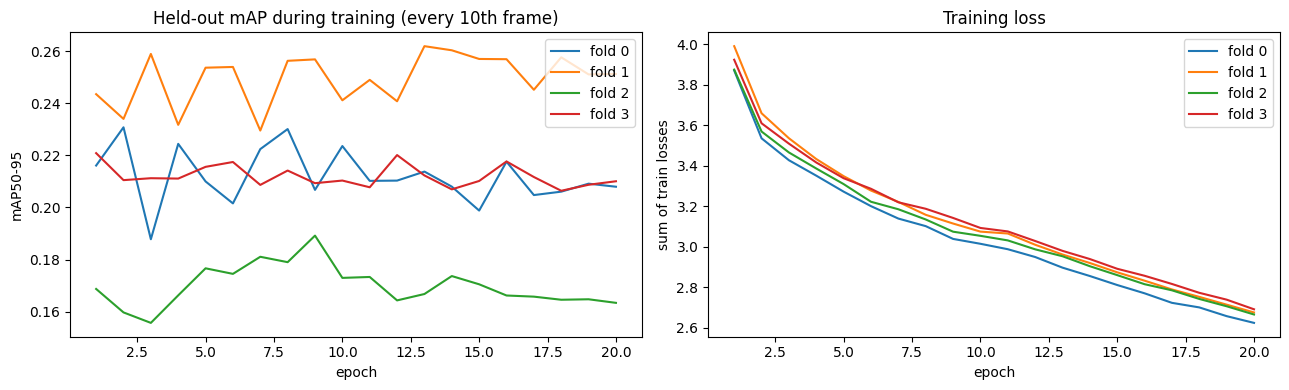

In [8]:
plot_curves(CFG["name"], N_FOLDS, WORK);

### Findings
**`last.pt` is kept.** In every fold the best epoch scores 0.011–0.026 mAP above the last one; choosing `best.pt`
on the held-out fold would inflate the OOF score by that much.

## Submission: ensemble of the 4 fold models
Every fold model predicts the test set; the boxes are fused by Weighted Boxes Fusion.
The model is evaluated out-of-fold above; the gain of the fold ensemble is measured on the public leaderboard.

In [9]:
test = pd.read_csv(DATA / "test_images.csv")
test_dets = fold_ensemble(CFG["name"], predict_fn, [str(DATA / f) for f in test["file_name"]], WORK)
write_submission(test_dets, test, WORK / f"submission_{CFG['name']}.csv").head()

fold 0 model: 948238 boxes
fold 1 model: 992247 boxes
fold 2 model: 834239 boxes
fold 3 model: 912727 boxes


,image_id,PredictionString
0,clip_001_0000001,0 0.6274 631.5 918.8 68.0 153.0 0 0.6167 777.0...
1,clip_001_0000002,0 0.6180 625.1 926.6 68.7 148.1 0 0.4993 774.6...
2,clip_001_0000003,0 0.4982 770.1 896.3 70.9 173.4 0 0.4842 1667....
3,clip_001_0000004,0 0.5558 701.2 903.9 66.5 168.6 0 0.4963 758.4...
4,clip_001_0000005,0 0.7166 560.4 968.0 70.3 110.8 0 0.6057 724.3...


### Findings
| Submission | Public LB |
|---|---:|
| single fold model | 0.173 |
| WBF ensemble of 4 fold models | **0.213** |